# **PROYECTO FINAL**

## Desafío: Predicción sobre calidad al final de una línea de tratamiento térmico

En este proyecto, se quiere realizar un modelo predictivo que permita conocer si ciertos tubos de acero que pasan por un tratamiento térmico resultan estar en norma o no. Esto permitiría realizar la inspección con mayor velocidad ya que se descartan aquellos tubos que el modelo indique que están fuera de norma.

Un tratamiento térmico es un proceso industrial que se lleva a cabo en piezas metálicas (en este caso tubos de acero) con el fin de mejorar sus propiedades mecánicas (fluencia, dureza y rotura). Se realiza bajo los principios de temple y revenido. 

Descripción del proceso

El revenido consiste en hacer pasar al tubo por hornos de inducción, los cuales por el principio de inducción electromagnética y por efecto joule elevan bruscamente la temperatura del tubo. Esto debe realizarse en tres zonas distintas ya que la temperatura debe ser uniforme en la sección del tubo (lo primero que se calienta es la parte externa del tubo, la parte interna tarda más).

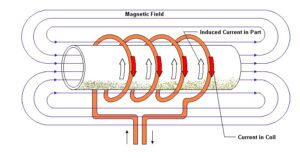

Luego viene la parte de temple. Aquí el tubo que se encuantra a una alta temperatura se enfría también bruscamente (templado) haciéndolo pasar por dentro de un tunel que larga grandes caudales de agua desde todas las direcciones.

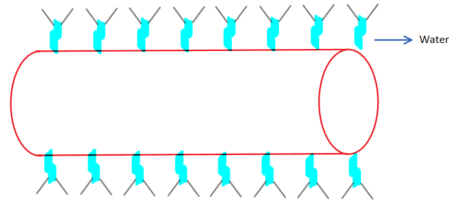

### Variables del dataset

**id**: identificación única de cada registro.

**colada**: la colada es anterior a la formación de los tubos. Es el proceso por el cual se forman, a través de la fundición de hierro, las barras de las que se fabrican los tubos.

**lote**: el lote es el grupo de tubos almacenados en conjunto (pueden provenir de diferentes coladas).

**nro_tubo**: número único que identifica al tubo.

**fecha**: número de fecha en la cual se le realizó el tratamiento térmico al tubo (se desconoce a qué fecha pertenece cada número)

**Ceq**: es el carbono equivalente. Este parámetro hace referencia a la composición química del acero en cuestión.

**Caudal**: es el caudal de agua que se suministra al momento del temple. Se mide en m^3/h.

**VelVia**: es la velocidad de via, es decir, la velocidad a la que avanzan los tubos por la línea. Se mide en mm/min.

**Ttemple**: temperatura de temple en °C.

**TZ1, TZ2, TZ3**: Temperaturas de zonas 1, 2 y 3 respectivamente. [°C]

**PermRev**: permanencia de revenido. Es el tiempo en el que se hace el revenido. Se encuentra en minutos.

**TRev**: temperatura de revenido en °C.

**Fluencia**: la fluencia es una de las propiedades mecánicas que se busca ajustar con el tratamiento térmico. El tubo se halla en norma si se encuentra entre 655 y 758.

**Rotura**: la rotura es otra de las propiedades mecánicas y para que esté en norma debe ser menor a 724.

**Dureza**: propiedad mecánica que está en norma si es mayor a 27.

**FN**: FN significa "fuera de norma". Si es '0' significa que está en norma y si es '1' quiere decir que el tubo está fuera de norma.





### Data Acquisition, Data Wrangling & Exploratory Data Analysis

In [1]:
#Importamos las librerias

# Operaciones Basicas
import numpy as np
import pandas as pd

# Visualizacion de Datos
import pandas_profiling
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive 
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [3]:
#Traemos el dataset crudo

df = pd.read_csv('gdrive/My Drive/Data Science (Equipo)/dataset/Tratamiento Termico de Piezas de Acero.csv', delimiter = ';')
df.head()

,id,colada,lote,nro_tubo,fecha,Ceq,Caudal,VelVia,Ttemple,TZ1,TZ2,TZ3,PermRev,TRev,Fluencia,Rotura,Dureza,FN
0,1,3000,100,1,737822,0.638758,512.338316,101.745428,24.595385,661.461695,677.564263,691.800781,61.168688,677.538061,638.819338,741.397506,22.290304,1
1,2,3000,100,2,737822,0.614585,497.800825,100.789383,23.035298,661.723399,681.466948,688.639275,62.137106,675.015220,632.789332,745.090905,22.058248,1
2,3,3000,100,3,737822,0.642772,505.705727,101.732095,23.651915,659.034791,679.185259,692.163955,61.755610,672.841299,686.624318,798.778804,24.030061,0
3,4,3000,100,5,737822,0.638038,488.697753,98.105294,25.707993,658.086237,678.136173,689.572197,60.053862,675.754787,678.813361,788.488974,23.892085,0
4,5,3000,100,7,737822,0.628711,503.931686,100.406438,27.464874,662.860603,679.614842,688.804030,61.616065,672.902279,678.527110,786.943061,23.729594,0


In [4]:
#Hacemos un shape contando la cantidad de datos y variables
df.shape

(1499, 18)

In [5]:
#Vemos los data types
df.dtypes

id            int64
colada        int64
lote          int64
nro_tubo      int64
fecha         int64
Ceq         float64
Caudal      float64
VelVia      float64
Ttemple     float64
TZ1         float64
TZ2         float64
TZ3         float64
PermRev     float64
TRev        float64
Fluencia    float64
Rotura      float64
Dureza      float64
FN            int64
dtype: object

No tenemos ningun object, por lo que no habrá que trabajar los tipos de datos.

In [6]:
#Contamos la cantidad de datos de las columnas
df.count()

id          1499
colada      1499
lote        1499
nro_tubo    1499
fecha       1499
Ceq         1499
Caudal      1499
VelVia      1499
Ttemple     1499
TZ1         1499
TZ2         1499
TZ3         1499
PermRev     1499
TRev        1499
Fluencia    1181
Rotura      1181
Dureza      1181
FN          1499
dtype: int64

Hay datos faltantes de las variables que indican las propiedades mecánicas de los tubos.

In [7]:
#Con info podemos ver de manera integrada algunas de las consultas anteriores
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1499 entries, 0 to 1498
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        1499 non-null   int64  
 1   colada    1499 non-null   int64  
 2   lote      1499 non-null   int64  
 3   nro_tubo  1499 non-null   int64  
 4   fecha     1499 non-null   int64  
 5   Ceq       1499 non-null   float64
 6   Caudal    1499 non-null   float64
 7   VelVia    1499 non-null   float64
 8   Ttemple   1499 non-null   float64
 9   TZ1       1499 non-null   float64
 10  TZ2       1499 non-null   float64
 11  TZ3       1499 non-null   float64
 12  PermRev   1499 non-null   float64
 13  TRev      1499 non-null   float64
 14  Fluencia  1181 non-null   float64
 15  Rotura    1181 non-null   float64
 16  Dureza    1181 non-null   float64
 17  FN        1499 non-null   int64  
dtypes: float64(12), int64(6)
memory usage: 210.9 KB


In [8]:
#Con describe podemos ver un resumen de estadistica descriptiva de los datos
df.describe().T    #Lo visualizamos transpuesto para ver la información completa sin necesidad de scrollear

,count,mean,std,min,25%,50%,75%,max
id,1499.0,750.000000,432.868340,1.000000,375.500000,750.000000,1124.500000,1499.000000
colada,1499.0,3447.698466,422.355560,3000.000000,3100.000000,3400.000000,3500.000000,4200.000000
lote,1499.0,270.533689,103.111063,100.000000,190.000000,260.000000,350.000000,480.000000
nro_tubo,1499.0,22.855237,14.270877,1.000000,11.000000,21.000000,35.000000,50.000000
fecha,1499.0,737976.022682,207.869531,737822.000000,737846.000000,737885.000000,737936.000000,738371.000000
Ceq,1499.0,0.643676,0.013019,0.605701,0.634832,0.642550,0.651844,0.691011
Caudal,1499.0,490.356281,23.719852,392.266762,486.097627,497.031160,505.394737,544.063322
VelVia,1499.0,99.990466,0.989114,96.415027,99.368069,99.956568,100.648691,103.012933
Ttemple,1499.0,39.978409,30.043457,21.150076,24.533638,25.282354,26.538875,112.327712
TZ1,1499.0,658.217746,8.644388,644.874399,650.301363,658.717758,661.245618,679.255453


In [9]:
#Comenzamos analizando una variable bien propia del tratamiento termico: la temperatura de temple
df.Ttemple.describe()

count    1499.000000
mean       39.978409
std        30.043457
min        21.150076
25%        24.533638
50%        25.282354
75%        26.538875
max       112.327712
Name: Ttemple, dtype: float64

Teniendo los datos así, no nos dicen mucho. Lo que si sorprende es que el maximo se encuentra muy alejado del resto de los estadísticos.

In [11]:
#Armamos un boxplot
from seaborn import boxplot
boxplot(df.Ttemple)

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


Se puede observar un gran desbalance.

In [12]:
#Hacemos un dsitplot para ver la distribucion de mejor manera
from seaborn import distplot
distplot(df.Ttemple)

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


Gran parte se acumula en una temperatura de temple de 25 y otra al rededor de los 100.

#### Realizamos un análisis similar con otra variable clave del tratamiento térmico: la temperatura de revenido

In [13]:
# Comenzamos con un diagrama de violin
from seaborn import violinplot
violinplot(df.TRev, data=df)

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


Aquí tambien se observa que los datos se encuentran concentrados en distintos grupos. Habrá que realizar análisis posteriores con el resto de las variables a modo de entender por qué ocurre esto.

#### Para finalizar el análisis univariado, veamos las proporciones de nuestra variable target

In [15]:
df.value_counts(df.FN, normalize=True)

FN
1    0.529686
0    0.470314
dtype: float64

Esta variable dicotómica se encuentra bastante balanceada. Es bueno para tener suficiente información de ambos resultados pero puede confundir si se interpreta fuera de contexto como la probabilidad de estar fuera de norma.

### Seguimos con un análisis bivariado

In [16]:
#Comenzamos con un heatmap
#Primero conviene quitar variables como id, nro_tubo y fecha
data_drop = df.drop(['id','nro_tubo','fecha'], axis=1)

plt.rcParams['figure.figsize'] = (20, 15)

sns.heatmap(data_drop.corr(), annot = True)
plt.title('Heatmap for the Dataset', fontsize = 20)
plt.show()

La alta correlacion entre las propiedades mecánicas no dice nada ya que por ciencia de los materiales sabemos que están relacionadas. Asimismo las correlaciones de las temperaturas de zona (TZ) tienen un alta correlación con  la temperatura de revenido y entre ellas, lo cual es lógico. El caudal es el caudal de temple, por eso cuanto más agua se tire por unidad de tiempo, más fría será la temperatura de temple. La colada y el lote también tienen alta correlación ya que se corresponden (los lotes se arman a partir de las coladas). 

In [17]:
#Buscamos ahora relaciones con diagramas de dispersión, para esto vamos a recortar algunas variables ya que no se ve mucho con todas
data_numeric = data_drop.drop(['colada','lote','TZ2','TZ3','Fluencia','Rotura','Dureza'], axis=1)

g = sns.PairGrid(data_numeric)
g.map_diag(sns.histplot)
g.map_offdiag(sns.scatterplot)
g.add_legend()

Se pueden ver ciertas nubes de puntos separadas entre si en varios graficos que tal vez nos den algo de información

In [18]:
#Buscamos relaciones
plt.rcParams['figure.figsize'] = (12, 9)
sns.violinplot(df['FN'], df['PermRev'], palette = 'colorblind')
plt.title('Relación entre Permanencia de revenido y Variable target', fontsize = 20, fontweight = 30)
plt.show()

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


La distribución de los tubos fuera de norma pasa los 80 minutos de permanencia de revenido. Este es un posible acercamiento para concluir que esa cantidad de tiempo puede resultar en que el tubo se encuentre fuera de norma.

In [19]:
#Vemos en un boxplot la relación de la variable target con la temperatura de revenido
plt.figure(figsize=(10,10)) #defino el tamaño del grafico
sns.boxplot(y = 'TRev', x = 'FN', data = df)
plt.title('Relación entre Temperatura de revenido y Variable target', fontsize = 15, fontweight = 20)
plt.show()

La temperatura de revenido deja al tubo fuera de norma más a altas temperaturas. Sin embargo vemos que hay que tener en cuenta más variables ya que ambas distribuciones van a lo largo de todo el rango de temperaturas. Un 25% de los datos de los tubos que no se encuentran fuera de norma, se halla ampliamente distribuido entre aproximadamente los 667°C y los 675°C.

### Nos adentramos a un Análsis Multivariado

In [20]:
#Pairplot
data_drop = df.drop(['id','nro_tubo','fecha'], axis=1)
data_numeric = data_drop.drop(['colada','lote','TZ2','TZ3','Fluencia','Rotura','Dureza'], axis=1)

sns.pairplot(data_numeric, hue ='FN', size = 3)

/usr/local/lib/python3.7/dist-packages/seaborn/axisgrid.py:2076: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


Ahora sí comenzamos a dilucidar datos importantes. Por ejemplo, en los gráficos de permanencia de revenido vemos siempre observaciones fuera de norma a partir de una permanencia de más de 75 minutos aproximadamente, sin embargo, la mayor concentración de los tubos que no se encuentran fuera de norma, está entre una permanencia de 50 y 75.

In [21]:
#Vemos de cerca la relación de la temperatura y permanencia de revenido
sns.FacetGrid(df,hue = 'FN' , size = 5).map(plt.scatter,'PermRev','TRev').add_legend();
plt.show()

/usr/local/lib/python3.7/dist-packages/seaborn/axisgrid.py:337: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


In [22]:
#Los clusters se generan porque cada lote tiene un tratamiento térmico similar. 
sns.FacetGrid(df,hue = 'FN' , size = 10).map(plt.scatter,'lote','TRev').add_legend();
plt.show()

/usr/local/lib/python3.7/dist-packages/seaborn/axisgrid.py:337: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


Vemos que los lotes se mueven en rangos relativamente pequeños de temperaturas, algunos con más dispersión que otros. También hay cambios de compórtamientos entre medio de ciertos lotes que separan grupos de lotes.

#### Realizamos un análisis de componentes principales

In [ ]:
#Vemos primero las componentes principales para ver la variabilidad que representan. (Empezamos con 4)

import plotly.express as px
from sklearn.decomposition import PCA

features = ['Ceq',	'Caudal',	'VelVia',	'Ttemple',	'TZ1',	'PermRev',	'TRev']

pca = PCA()
components = pca.fit_transform(df[features])
labels = {
    str(i): f"PC {i+1} ({var:.1f}%)"
    for i, var in enumerate(pca.explained_variance_ratio_ * 100)
}

fig = px.scatter_matrix(
    components,
    labels=labels,
    dimensions=range(4),
    color=df["FN"]
)
fig.update_traces(diagonal_visible=False)
fig.show()

La variabilidad en 2 dimensiones es significativa (90%), por lo que procedemos a realizar un análisis con PC1 y PC2.

In [ ]:
from sklearn.preprocessing import StandardScaler

X = df[features]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

fig = px.scatter(components, x=0, y=1, color=df['FN'])

for i, feature in enumerate(features):
    fig.add_shape(
        type='line',
        x0=0, y0=0,
        x1=loadings[i, 0],
        y1=loadings[i, 1]
    )
    fig.add_annotation(
        x=loadings[i, 0],
        y=loadings[i, 1],
        ax=0, ay=0,
        xanchor="center",
        yanchor="bottom",
        text=feature,
    )
fig.show()

No se pueden extraer muchas conclusiones. Se ve que claramente un aumento de la permanencia de revenido lleva a que los tubos estén fuera de norma, ya que los puntos azules se acercan a una linea casi perpendicular de la componente de PermRev en cero.

# Comparación de Modelos

In [23]:
data_numeric = df.drop(['id','fecha','nro_tubo','colada','lote','TZ1','TZ2','TZ3','Fluencia','Rotura','Dureza'], axis=1) #sacamos variables porque no hacen al modelo o por su alta correlacion
data_numeric.head()

,Ceq,Caudal,VelVia,Ttemple,PermRev,TRev,FN
0,0.638758,512.338316,101.745428,24.595385,61.168688,677.538061,1
1,0.614585,497.800825,100.789383,23.035298,62.137106,675.015220,1
2,0.642772,505.705727,101.732095,23.651915,61.755610,672.841299,0
3,0.638038,488.697753,98.105294,25.707993,60.053862,675.754787,0
4,0.628711,503.931686,100.406438,27.464874,61.616065,672.902279,0


In [24]:
#Seperamos en X e y
X = data_numeric.drop("FN", axis=1) #Elimino de mi dataset la variable a predecir
y = data_numeric.FN #Defino el Target

In [25]:
#Importamos la libreria para separar en train y test
from sklearn.model_selection import train_test_split 

#Me quedo con 30% para test y 70% para train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42) 

### Árbol de Decision

In [26]:
from sklearn.tree import DecisionTreeClassifier #Importamos el modelo
tree = DecisionTreeClassifier(max_depth=15, random_state = 42) #Creamos el modelo

In [27]:
#Entrenamos el modelo
tree.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=15, random_state=42)

In [28]:
y_train_pred = tree.predict(X_train) #Prediccion en Train
y_test_pred = tree.predict(X_test) #Prediccion en Test

In [29]:
from sklearn.metrics import accuracy_score

#Calculo el accuracy en Train
train_accuracy = accuracy_score(y_train, y_train_pred)

#Calculo el accuracy en Test
test_accuracy = accuracy_score(y_test, y_test_pred)

print('% de aciertos sobre el set de entrenamiento:', train_accuracy)
print('% de aciertos sobre el set de evaluación:',test_accuracy)

% de aciertos sobre el set de entrenamiento: 0.994280266920877
% de aciertos sobre el set de evaluación: 0.8044444444444444


In [30]:
#Creamos la matriz de confusión
from sklearn.metrics import confusion_matrix
matriz = confusion_matrix(y_test, y_test_pred)
print('Matriz de Confusión:')
print(matriz)

Matriz de Confusión:
[[180  43]
 [ 45 182]]


De 180 tubos que estaban en norma y 182 que no, el modelo acertó en ambos casos. Por otro lado, el modelo predijo que 45 tubos estaban en norma cuando no era asi y predijo que habia 43 tubos fuera de norma cuando estaban en norma.

### Entrenamiento del modelo (RF)

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

RFC = RandomForestClassifier(random_state=11, n_estimators=100,
                               class_weight="balanced", max_features="log2")
RFC.fit(X_train, y_train)

y_train_pred = RFC.predict(X_train)
y_test_pred = RFC.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print('% de aciertos sobre el set de entrenamiento:', train_accuracy)
print('% de aciertos sobre el set de evaluación:',test_accuracy)

% de aciertos sobre el set de entrenamiento: 1.0
% de aciertos sobre el set de evaluación: 0.8422222222222222


In [34]:
]#Creamos la matriz de confusión
from sklearn.metrics import confusion_matrix
matriz = confusion_matrix(y_test, y_test_pred)
print('Matriz de Confusión:')
print(matriz)

SyntaxError: ignored

Ahora probamos con cambios en los hiperparámetros para analizar cuál es la mejor opción.

In [35]:
#Hypertuning utilizando grid search
from sklearn.model_selection import GridSearchCV

random_forest = RandomForestClassifier()

#Definimos los parámetros de búsqueda
params = {
    'n_estimators' : [100, 200, 500],
    'max_features': [2,3]
}

grid_random_forest = GridSearchCV(estimator = random_forest,
                                  param_grid = params,
                                  scoring = 'accuracy',  # 
                                  cv = 5, 
                                  verbose = 1, #Muestra el resultado en pantalla
                                  n_jobs = -1) # corrida en paralelo

In [36]:
#Entrenamos el modelo
grid_random_forest.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_features': [2, 3],
                         'n_estimators': [100, 200, 500]},
             scoring='accuracy', verbose=1)

In [37]:
#Obtenemos el mejor modelo!
grid_random_forest.best_estimator_

RandomForestClassifier(max_features=3, n_estimators=500)

In [38]:
grid_random_forest.best_score_

0.8541535657325131

In [ ]:
#Hacemos de nuevo el hypertuning (aumentamos max_features)
params = {
    'n_estimators' : [100, 200, 500],
    'max_features': [4,5]
}

grid_random_forest = GridSearchCV(estimator = random_forest,
                                  param_grid = params,
                                  scoring = 'accuracy',  # 
                                  cv = 5, 
                                  verbose = 1, #Muestra el resultado en pantalla
                                  n_jobs = -1) # corrida en paralelo

#Entrenamos el modelo
grid_random_forest.fit(X_train, y_train)

grid_random_forest.best_estimator_

Fitting 5 folds for each of 6 candidates, totalling 30 fits


RandomForestClassifier(max_features=5, n_estimators=500)

In [ ]:
grid_random_forest.best_score_

0.8579539758487126

In [ ]:
#Hacemos de nuevo el hypertuning (aumentamos n_estimators)
params = {
    'n_estimators' : [400, 500, 600],
    'max_features': [3,4]
}

grid_random_forest = GridSearchCV(estimator = random_forest,
                                  param_grid = params,
                                  scoring = 'accuracy',  # 
                                  cv = 5, 
                                  verbose = 1, #Muestra el resultado en pantalla
                                  n_jobs = -1) # corrida en paralelo

#Entrenamos el modelo
grid_random_forest.fit(X_train, y_train)

print(grid_random_forest.best_estimator_)

print(grid_random_forest.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
RandomForestClassifier(max_features=3, n_estimators=400)
0.8560492139439507


In [ ]:
#Decidimos quedarnos con max_features=4, n_estimators=500 (aunque difiere muy poco el accuracy)

RFC = RandomForestClassifier(max_features=4, n_estimators=500)

RFC.fit(X_train, y_train)

y_train_pred = RFC.predict(X_train)
y_test_pred = RFC.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print('% de aciertos sobre el set de entrenamiento:', train_accuracy)
print('% de aciertos sobre el set de evaluación:',test_accuracy)

% de aciertos sobre el set de entrenamiento: 1.0
% de aciertos sobre el set de evaluación: 0.84


In [ ]:
#Creamos la matriz de confusión
from sklearn.metrics import confusion_matrix
matriz = confusion_matrix(y_test, y_test_pred)
print('Matriz de Confusión:')
print(matriz)

Matriz de Confusión:
[[185  38]
 [ 34 193]]


#### Curva ROC

In [ ]:
# Hacemos uso de una métrica diferente para analizar el modelo

from sklearn.metrics import roc_curve, auc

fpr, tpr, threshold = roc_curve(y_test, y_test_pred)
roc_auc = auc(fpr, tpr)

# AUC
print(f"AUC for our classifier is: {roc_auc}")

# Gráfica de la Curva ROC
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

AUC for our classifier is: 0.8399083384366172


Es un valor aceptable de AUC

#### Ajustamos los pesos de las clases

In [ ]:
# Se prefiere que la predicción diga que el tubo está en norma cuando no lo está debido a que estos tubos igual pasan por la inspección.

RFC = RandomForestClassifier(random_state=11, max_features=4, n_estimators=500, class_weight={0:5,1:1})

RFC.fit(X_train, y_train)

y_train_pred = RFC.predict(X_train)
y_test_pred = RFC.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print('% de aciertos sobre el set de entrenamiento:', train_accuracy)
print('% de aciertos sobre el set de evaluación:',test_accuracy)

% de aciertos sobre el set de entrenamiento: 1.0
% de aciertos sobre el set de evaluación: 0.84


In [ ]:
from sklearn.metrics import confusion_matrix
matriz = confusion_matrix(y_test, y_test_pred)
print('Matriz de Confusión:')
print(matriz)

Matriz de Confusión:
[[184  39]
 [ 33 194]]
